# Feature redundancy
Area and Convex_Area show very similar distributions, as observed from their boxplots and descriptive statistics. The scatter plot also shows an extremely strong linear relationship between the two features, which is supported by their correlation coefficient of approximately 1.00. Both features exhibit similar class patterns. Therefore, Area and Convex_Area contain highly similar information and may be redundant. To reduce potential redundancy in SVM, we will evaluate a reduced feature set by removing one of these features and compare its performance with the model using both features.

In [1]:
features_set1 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set2 = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set3 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']

# Train/test split

In [2]:
import pandas as pd

train_set1 = pd.read_csv("train_set1.csv")

X_train_set1 = train_set1.drop(columns=["Target"])
y_train_set1 = train_set1["Target"]

train_set2 = pd.read_csv("train_set2.csv")

X_train_set2 = train_set2.drop(columns=["Target"])
y_train_set2 = train_set2["Target"]

train_set3 = pd.read_csv("train_set3.csv")

X_train_set3 = train_set3.drop(columns=["Target"])
y_train_set3 = train_set3["Target"]

# Train without using 'Convex_Area' (Set 3)

# Feature scaling

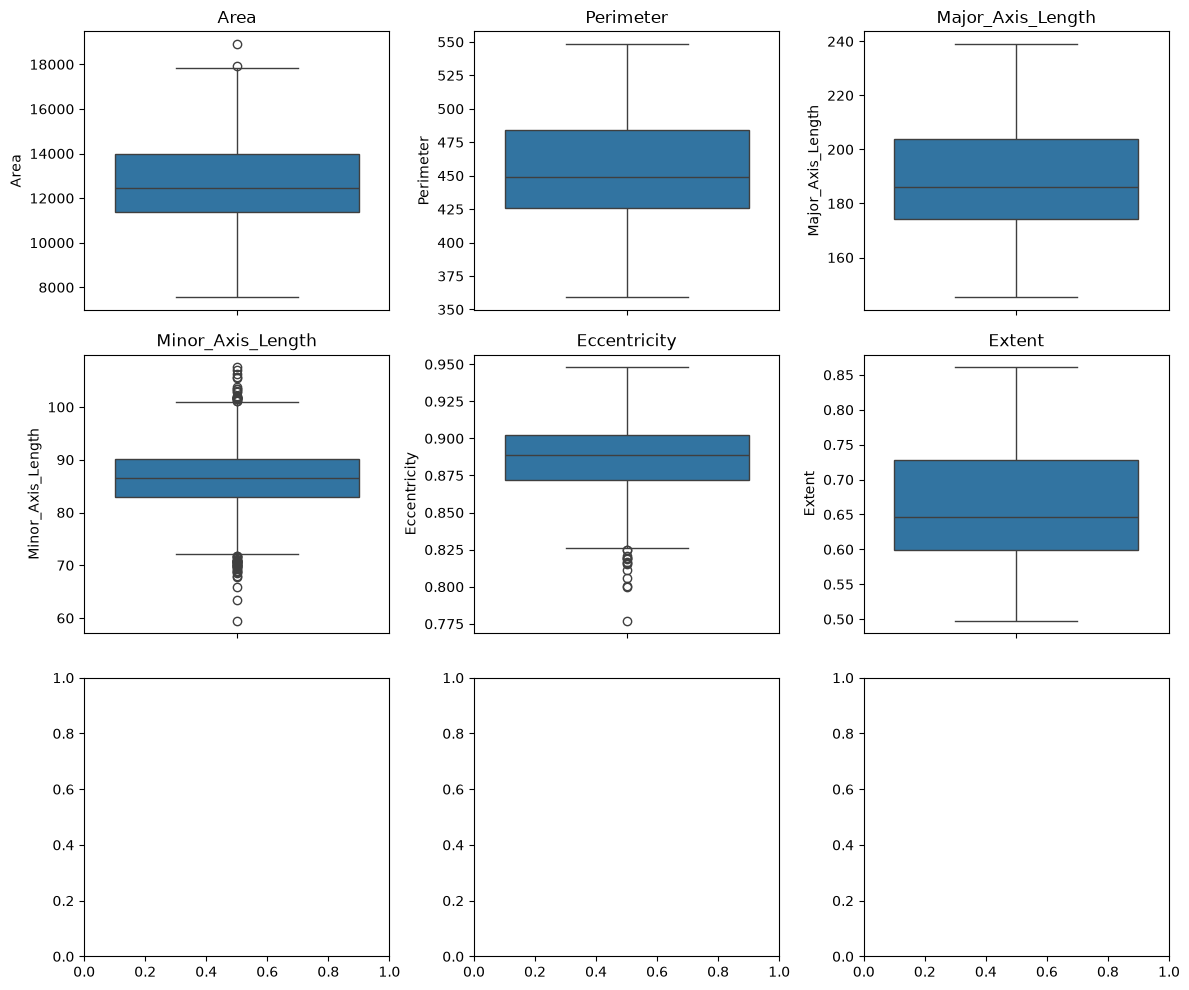

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(X_train_set3):
    sns.boxplot(y=X_train_set3[col], ax=axes[i])
    axes[i].set_title(col)


plt.tight_layout()
plt.show()

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [7]:
features_outliers_set3 = ['Eccentricity', 'Minor_Axis_Length', 'Area']
features_non_outliers_set3  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set3[features_non_outliers_set3])

In [9]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set3[features_outliers_set3])

In [10]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set3,
        index=X_train_set3.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set3,
        index=X_train_set3.index
    )
], axis=1)

In [11]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

# Create the model
svm_model = SVC(
    kernel='rbf',
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    svm_model,
    X_train_scaled,
    y_train_set3,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [12]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93355209 0.93109106 0.9319114  0.93849938 0.93234932]
Validation accuracy: [0.93770492 0.93934426 0.93442623 0.91625616 0.9408867 ]
Mean training accuracy: 0.9334806522798615
Mean validation accuracy: 0.9337236533957846
Validation accuracy std: 0.008992863430922208
Mean F1: 0.9322744099262519
Mean Precision: 0.9327770804203727
Mean Recall: 0.9319316484216198


## Hyperparameter tuning

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Preprocessing
preprocessor_svm = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set3),
    ('robust', RobustScaler(), features_outliers_set3)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# SVM pipeline
pipeline_svm = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC())
])

# Hyperparameter grid
param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

# Grid Search
grid_search_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_svm.fit(X_train_set3, y_train_set3)

print("Best Parameters:", grid_search_svm.best_params_)
print("Best CV Accuracy:", grid_search_svm.best_score_)

Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV Accuracy: 0.9320848475059893


In [14]:
results = pd.DataFrame(grid_search_svm.cv_results_)
best_results = results.loc[grid_search_svm.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_svm.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Mean Train Accuracy:      0.9328
Mean CV Accuracy:         0.9321
Mean CV Precision:        0.9310
Mean CV Recall:           0.9306
Mean CV F1-Score:         0.9306
Train-CV Accuracy Gap:    0.0007
No strong overfitting signal based on this accuracy gap.


In [15]:
# Obtain best model

best_svm_model = grid_search_svm.best_estimator_

# Train without using 'Area' (Set 2)

# Feature scaling

In [16]:
features_outliers_set2 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area']
features_non_outliers_set2  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [18]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set2[features_non_outliers_set2])

In [19]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set2[features_outliers_set2])

In [20]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set2,
        index=X_train_set2.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set2,
        index=X_train_set2.index
    )
], axis=1)

In [21]:
# Create the model
svm_model = SVC(
    kernel='rbf',
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    svm_model,
    X_train_scaled,
    y_train_set2,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [22]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93314192 0.93273175 0.9319114  0.93808938 0.93234932]
Validation accuracy: [0.93770492 0.93770492 0.93442623 0.91789819 0.94252874]
Mean training accuracy: 0.933644754823266
Mean validation accuracy: 0.9340525989932434
Validation accuracy std: 0.008480898174701434
Mean F1: 0.9326163820285261
Mean Precision: 0.93309196832443
Mean Recall: 0.9323162638062351


## Hyperparameter tuning

In [23]:
# Preprocessing
preprocessor_svm = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set2),
    ('robust', RobustScaler(), features_outliers_set2)
])

# SVM pipeline
pipeline_svm = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC(probability=True))
])

# Hyperparameter grid
param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Grid Search
grid_search_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_svm.fit(X_train_set2, y_train_set2)

print("Best Parameters:", grid_search_svm.best_params_)
print("Best CV Accuracy:", grid_search_svm.best_score_)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV Accuracy: 0.9340542141107433


In [24]:
# Obtain best model

best_svm_model = grid_search_svm.best_estimator_

In [25]:
results = pd.DataFrame(grid_search_svm.cv_results_)
best_results = results.loc[grid_search_svm.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_svm.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Mean Train Accuracy:      0.9345
Mean CV Accuracy:         0.9341
Mean CV Precision:        0.9327
Mean CV Recall:           0.9330
Mean CV F1-Score:         0.9327
Train-CV Accuracy Gap:    0.0004
No strong overfitting signal based on this accuracy gap.


# Train with using all features (Set 1)

# Feature scaling

In [26]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Area', 'Convex_Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [27]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set1[features_non_outliers_set1])

In [28]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set1[features_outliers_set1])

In [29]:
# Combine the scaled features
X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set1,
        index=X_train_set1.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set1,
        index=X_train_set1.index
    )
], axis=1)

In [30]:
# Create the model
svm_model = SVC(
    kernel='rbf',
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    svm_model,
    X_train_scaled,
    y_train_set1,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [31]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93314192 0.93150123 0.93109106 0.93890939 0.93316933]
Validation accuracy: [0.93606557 0.93934426 0.93606557 0.91297209 0.94252874]
Mean training accuracy: 0.9335625858309445
Mean validation accuracy: 0.9333952461708256
Validation accuracy std: 0.010489787586164789
Mean F1: 0.9319614518084729
Mean Precision: 0.9323812030774963
Mean Recall: 0.9317417242814929


## Hyperparameter tuning

In [32]:
# Preprocessing
preprocessor_svm = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set1),
    ('robust', RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# SVM pipeline
pipeline_svm = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC())
])

# Hyperparameter grid
param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

# Grid Search
grid_search_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_svm.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_svm.best_params_)
print("Best CV Accuracy:", grid_search_svm.best_score_)

Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV Accuracy: 0.9353656895205793


In [33]:
# Obtain best model

best_svm_model = grid_search_svm.best_estimator_

In [34]:

import joblib
from datetime import datetime

# 1. Get the best tuned SVM pipeline
final_svm_set1 = grid_search_svm.best_estimator_

# 2. Store the selected model and its metadata
model_bundle = {
    "model": final_svm_set1,
    "model_name": "SVM - Set 1",
    "feature_names": X_train_set1.columns.tolist(),
    "hyperparameters": grid_search_svm.best_params_,
    "cv_metrics": {
        "mean_cv_accuracy": float(
            grid_search_svm.cv_results_[
                "mean_test_accuracy"
            ][grid_search_svm.best_index_]
        ),
        "precision_macro": float(
            grid_search_svm.cv_results_[
                "mean_test_precision"
            ][grid_search_svm.best_index_]
        ),
        "recall_macro": float(
            grid_search_svm.cv_results_[
                "mean_test_recall"
            ][grid_search_svm.best_index_]
        ),
        "f1_macro": float(
            grid_search_svm.cv_results_[
                "mean_test_f1"
            ][grid_search_svm.best_index_]
        )
    },
    "saved_at": datetime.now().isoformat()
}

# 3. Save the bundle
joblib.dump(model_bundle, "svm_set1.joblib")

print("SVM Set 1 model saved successfully!")
print("File: svm_set1.joblib")
print("Best parameters:", model_bundle["hyperparameters"])
print("Features:", model_bundle["feature_names"])
print(
    "Mean CV accuracy:",
    f"{model_bundle['cv_metrics']['mean_cv_accuracy']:.2%}"
)


SVM Set 1 model saved successfully!
File: svm_set1.joblib
Best parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Features: ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
Mean CV accuracy: 93.54%


In [35]:
results = pd.DataFrame(grid_search_svm.cv_results_)
best_results = results.loc[grid_search_svm.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_svm.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Mean Train Accuracy:      0.9359
Mean CV Accuracy:         0.9354
Mean CV Precision:        0.9341
Mean CV Recall:           0.9341
Mean CV F1-Score:         0.9340
Train-CV Accuracy Gap:    0.0006
No strong overfitting signal based on this accuracy gap.


# Evaluate models removing outliers

## Outlier distribution of training and testing set
(Model without redundant feature 'Area')

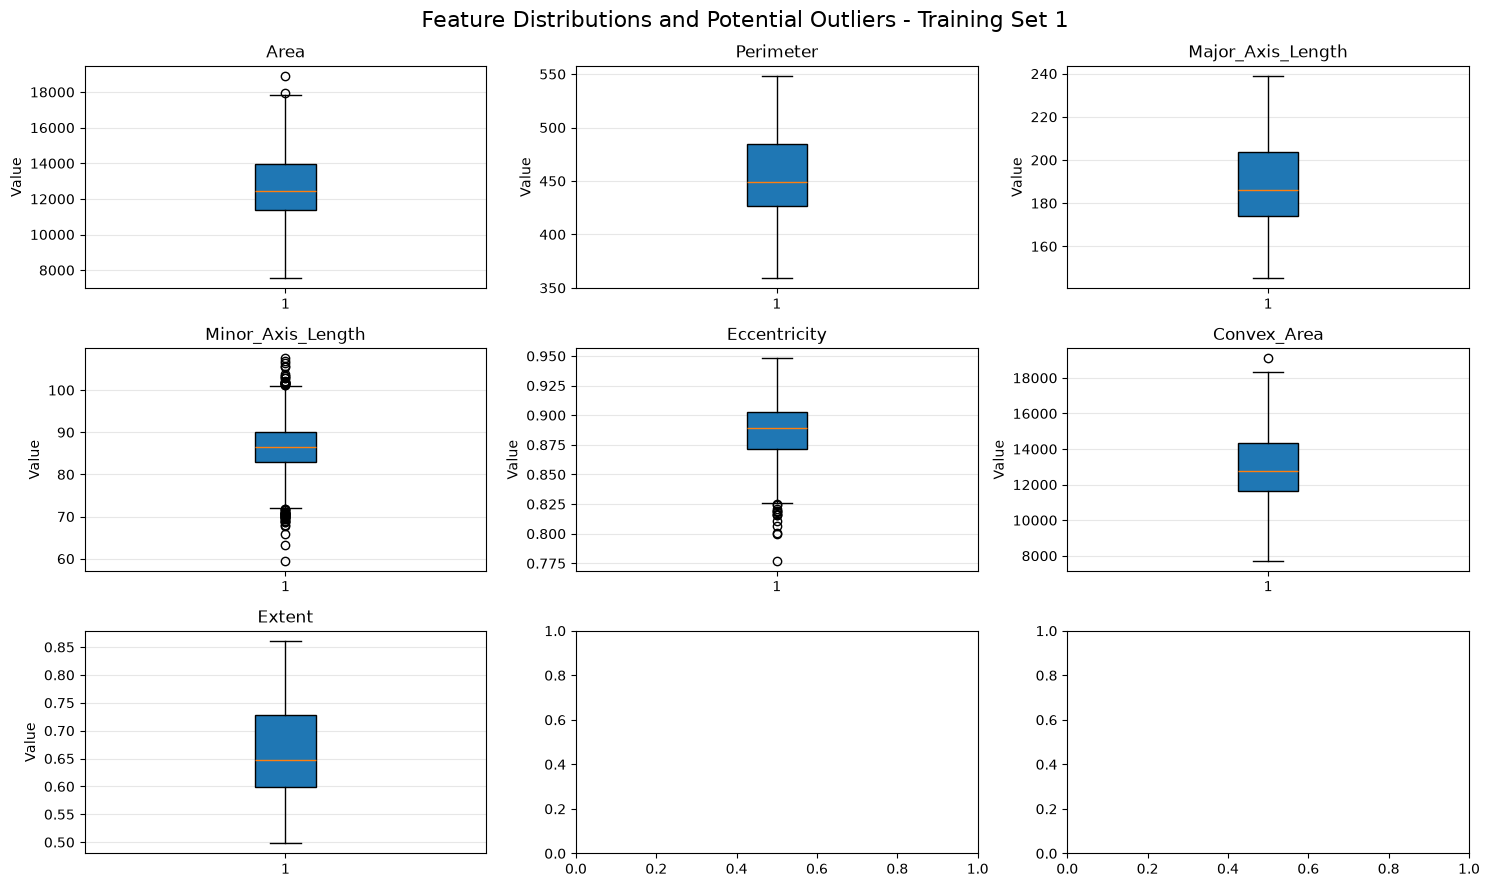

In [36]:
features_set2 = X_train_set1.columns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set2):
    axes[i].boxplot(
        X_train_set1[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

In training set, Minor_Axis_Length, Eccentricity and Convex area has outliers.

In [37]:
outlier_features = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area"
]

X_train_set1_clean = X_train_set1.copy()
y_train_set1_clean = y_train_set1.copy()

for feature in outlier_features:

    Q1 = X_train_set1_clean[feature].quantile(0.25)
    Q3 = X_train_set1_clean[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        (X_train_set1_clean[feature] >= lower_bound) &
        (X_train_set1_clean[feature] <= upper_bound)
    )

    X_train_set1_clean = X_train_set1_clean[mask]
    y_train_set1_clean = y_train_set1_clean.loc[X_train_set1_clean.index]

    print(f"{feature}")
    print(f"Lower bound: {lower_bound:.4f}")
    print(f"Upper bound: {upper_bound:.4f}")
    print(f"Remaining rows: {len(X_train_set1_clean)}")
    print()

Minor_Axis_Length
Lower bound: 71.9833
Upper bound: 101.0960
Remaining rows: 2991

Eccentricity
Lower bound: 0.8261
Upper bound: 0.9477
Remaining rows: 2977

Convex_Area
Lower bound: 7690.0000
Upper bound: 18290.0000
Remaining rows: 2977



In [38]:
# Removed rows count
print("Original training rows:", len(X_train_set1))
print("Clean training rows:", len(X_train_set1_clean))
print("Rows removed:", len(X_train_set1) - len(X_train_set1_clean))

Original training rows: 3048
Clean training rows: 2977
Rows removed: 71


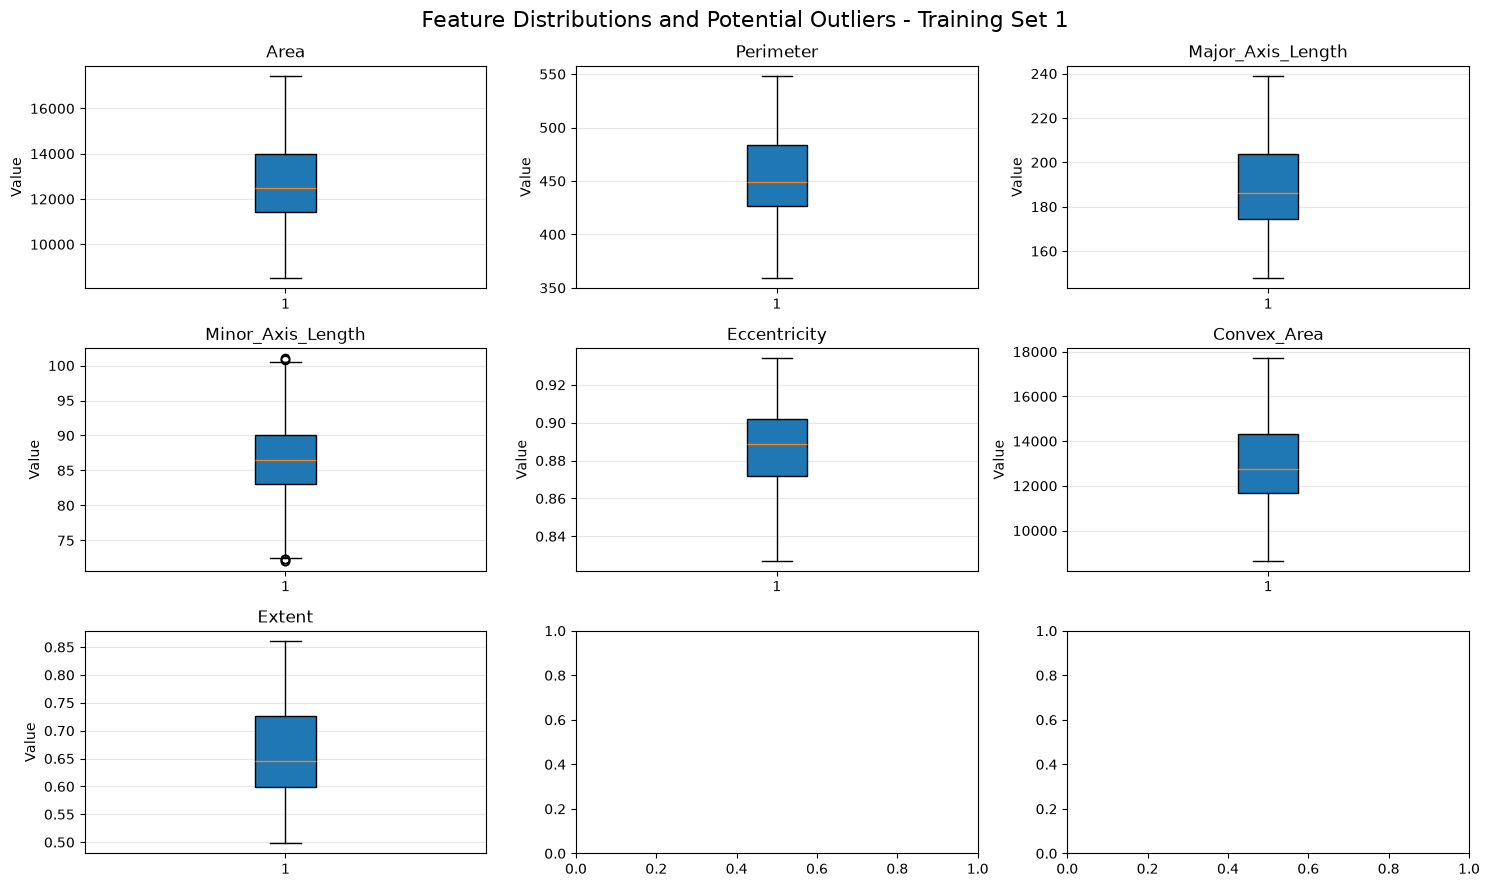

In [39]:
features_set2 = X_train_set1_clean.columns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set2):
    axes[i].boxplot(
        X_train_set1_clean[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Train (Set 1)

# Feature scaling

In [40]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area', 'Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [41]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set1_clean[features_non_outliers_set1])

In [42]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set1_clean[features_outliers_set1])

In [43]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set1,
        index=X_train_set1_clean.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set1,
        index=X_train_set1_clean.index
    )
], axis=1)

In [44]:
# Create the model
svm_model = SVC(
    kernel='rbf',
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    svm_model,
    X_train_scaled,
    y_train_set1_clean,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [45]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93154137 0.93196136 0.93240974 0.93282955 0.93450882]
Validation accuracy: [0.93288591 0.93624161 0.93277311 0.92773109 0.92268908]
Mean training accuracy: 0.9326501681553271
Mean validation accuracy: 0.9304641588178896
Validation accuracy std: 0.004743345502643505
Mean F1: 0.9290549224258878
Mean Precision: 0.9295768171577132
Mean Recall: 0.928935169559973


## Hyperparameter tuning

In [46]:
# Preprocessing
preprocessor_svm = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set1),
    ('robust', RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# SVM pipeline
pipeline_svm = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC())
])

# Hyperparameter grid
param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

# Grid Search
grid_search_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_svm.fit(X_train_set1_clean, y_train_set1_clean)

print("Best Parameters:", grid_search_svm.best_params_)
print("Best CV Accuracy:", grid_search_svm.best_score_)

Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV Accuracy: 0.9338238114037563


In [47]:
# Obtain best model

best_svm_model = grid_search_svm.best_estimator_

In [48]:
results = pd.DataFrame(grid_search_svm.cv_results_)
best_results = results.loc[grid_search_svm.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_svm.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Mean Train Accuracy:      0.9349
Mean CV Accuracy:         0.9338
Mean CV Precision:        0.9326
Mean CV Recall:           0.9327
Mean CV F1-Score:         0.9325
Train-CV Accuracy Gap:    0.0011
No strong overfitting signal based on this accuracy gap.


# Check class imbalance

In [49]:
class_distribution = pd.DataFrame({
    "Count": y_train_set1.value_counts(),
    "Percentage": y_train_set1.value_counts(normalize=True) * 100
})

print(class_distribution)

          Count  Percentage
Target                     
Osmancik   1744   57.217848
Cammeo     1304   42.782152


### Balance the classes using SMOTE

In [50]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_set1_balanced, y_train_set1_balanced = smote.fit_resample(
    X_train_set1,
    y_train_set1
)

In [51]:
class_distribution_balanced = pd.DataFrame({
    "Count": y_train_set1_balanced.value_counts(),
    "Percentage": y_train_set1_balanced.value_counts(normalize=True) * 100
})

print(class_distribution_balanced)

          Count  Percentage
Target                     
Osmancik   1744        50.0
Cammeo     1744        50.0


### Train the final selected model

# Train without using 'Area' (Set 2)

# Feature scaling

In [52]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area', 'Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [53]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set1_balanced[features_non_outliers_set1])

In [54]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set1_balanced[features_outliers_set1])

In [55]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set1,
        index=X_train_set1_balanced.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set1,
        index=X_train_set1_balanced.index
    )
], axis=1)

In [56]:
# Create the model
svm_model = SVC(
    kernel='rbf',
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    svm_model,
    X_train_scaled,
    y_train_set1_balanced,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [57]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.9311828  0.92903226 0.93010753 0.94195629 0.92977427]
Validation accuracy: [0.93696275 0.93982808 0.93982808 0.89239598 0.93830703]
Mean training accuracy: 0.9324106286335109
Mean validation accuracy: 0.9294643848174534
Validation accuracy std: 0.018565002891456198
Mean F1: 0.9294565468619644
Mean Precision: 0.9296948135916837
Mean Recall: 0.9294667852320257


## Hyperparameter tuning

In [58]:

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Preprocessing
preprocessor_svm = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set1),
    ('robust', RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Pipeline: scaling -> SMOTE -> SVM
pipeline_svm_smote = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('smote', SMOTE(random_state=42)),
    ('model', SVC())
])

# Hyperparameter grid
param_grid_svm_smote = {
    'model__C': [0.1, 1, 10, 100],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

# Grid search
grid_search_svm_smote = GridSearchCV(
    estimator=pipeline_svm_smote,
    param_grid=param_grid_svm_smote,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train on the original training data
grid_search_svm_smote.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_svm_smote.best_params_)
print("Best CV Accuracy:", grid_search_svm_smote.best_score_)

# Final test evaluation
best_svm_smote = grid_search_svm_smote.best_estimator_

Best Parameters: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV Accuracy: 0.9330684540633664


In [59]:
results = pd.DataFrame(grid_search_svm_smote.cv_results_)
best_results = results.loc[grid_search_svm_smote.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_svm_smote.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Mean Train Accuracy:      0.9377
Mean CV Accuracy:         0.9331
Mean CV Precision:        0.9309
Mean CV Recall:           0.9334
Mean CV F1-Score:         0.9319
Train-CV Accuracy Gap:    0.0046
No strong overfitting signal based on this accuracy gap.


# Forward feature selection

In [60]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [61]:
# Use the selected configuration from your notebook
svm_model = SVC(
    kernel="linear",
    C=10,
    gamma="scale",
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [62]:
def build_svm_pipeline(selected_features):

    selected_features = list(selected_features)

    standard_features = [
        f for f in features_non_outliers_set1
        if f in selected_features
    ]

    robust_features = [
        f for f in features_outliers_set1
        if f in selected_features
    ]

    transformers = []

    if standard_features:
        transformers.append(
            ("standard", StandardScaler(), standard_features)
        )

    if robust_features:
        transformers.append(
            ("robust", RobustScaler(), robust_features)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", clone(svm_model))
    ])

    return pipeline

In [63]:
remaining_features = X_train_set1.columns.tolist()
selected_features = []
ffs_results = []

while remaining_features:

    candidate_results = []

    for feature in remaining_features:

        candidate_features = selected_features + [feature]

        pipeline = build_svm_pipeline(candidate_features)

        scores = cross_val_score(
            pipeline,
            X_train_set1[candidate_features],
            y_train_set1,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )

        candidate_results.append({
            "Feature": feature,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    # Select the best feature to add at this step
    candidate_results.sort(
        key=lambda x: x["Mean CV Accuracy"],
        reverse=True
    )

    best_candidate = candidate_results[0]

    selected_features.append(best_candidate["Feature"])
    remaining_features.remove(best_candidate["Feature"])

    
from sklearn.model_selection import cross_validate

# Evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

remaining_features = X_train_set1.columns.tolist()
selected_features = []
ffs_results = []

while remaining_features:

    candidate_results = []

    for feature in remaining_features:

        candidate_features = selected_features + [feature]

        pipeline = build_svm_pipeline(candidate_features)

        scores = cross_validate(
            pipeline,
            X_train_set1[candidate_features],
            y_train_set1,
            cv=cv,
            scoring=scoring_metrics,
            return_train_score=True,
            n_jobs=-1
        )

        candidate_results.append({
            "Feature": feature,
            "Train Accuracy": scores["train_accuracy"].mean(),
            "Mean CV Accuracy": scores["test_accuracy"].mean(),
            "CV Std": scores["test_accuracy"].std(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1-Score": scores["test_f1"].mean()
        })

    # Select the feature with the highest mean CV accuracy
    candidate_results.sort(
        key=lambda x: x["Mean CV Accuracy"],
        reverse=True
    )

    best_candidate = candidate_results[0]

    selected_features.append(best_candidate["Feature"])
    remaining_features.remove(best_candidate["Feature"])

    ffs_results.append({
        "Step": len(selected_features),
        "Added Feature": best_candidate["Feature"],
        "Selected Features": selected_features.copy(),
        "Number of Features": len(selected_features),
        "Train Accuracy": best_candidate["Train Accuracy"],
        "Mean CV Accuracy": best_candidate["Mean CV Accuracy"],
        "CV Std": best_candidate["CV Std"],
        "Precision": best_candidate["Precision"],
        "Recall": best_candidate["Recall"],
        "F1-Score": best_candidate["F1-Score"]
    })

# Create and display the results table
ffs_df = pd.DataFrame(ffs_results)

display(
    ffs_df[
        [
            "Step",
            "Added Feature",
            "Selected Features",
            "Number of Features",
            "Train Accuracy",
            "Mean CV Accuracy",
            "CV Std",
            "Precision",
            "Recall",
            "F1-Score"
        ]
    ].round(4)
)

# Find the best feature subset
best_step_index = ffs_df["Mean CV Accuracy"].idxmax()
best_ffs_row = ffs_df.loc[best_step_index]

best_features_ffs = best_ffs_row["Selected Features"]

print("\nBest feature subset:", best_features_ffs)
print("Number of features:", len(best_features_ffs))
print("Train accuracy:", round(best_ffs_row["Train Accuracy"], 4))
print("Mean CV accuracy:", round(best_ffs_row["Mean CV Accuracy"], 4))
print("CV standard deviation:", round(best_ffs_row["CV Std"], 4))
print("Macro precision:", round(best_ffs_row["Precision"], 4))
print("Macro recall:", round(best_ffs_row["Recall"], 4))
print("Macro F1-score:", round(best_ffs_row["F1-Score"], 4))


,Step,Added Feature,Selected Features,Number of Features,Train Accuracy,Mean CV Accuracy,CV Std,Precision,Recall,F1-Score
0,1,Major_Axis_Length,[Major_Axis_Length],1,0.9301,0.9301,0.0096,0.9286,0.9291,0.9287
1,2,Perimeter,"[Major_Axis_Length, Perimeter]",2,0.9326,0.9318,0.0119,0.9306,0.9303,0.9303
2,3,Extent,"[Major_Axis_Length, Perimeter, Extent]",3,0.9318,0.9321,0.0108,0.9306,0.9309,0.9307
3,4,Convex_Area,"[Major_Axis_Length, Perimeter, Extent, Convex_...",4,0.9323,0.9327,0.0102,0.9313,0.9317,0.9314
4,5,Area,"[Major_Axis_Length, Perimeter, Extent, Convex_...",5,0.9365,0.9350,0.0076,0.9340,0.9336,0.9337
5,6,Eccentricity,"[Major_Axis_Length, Perimeter, Extent, Convex_...",6,0.9367,0.9347,0.0065,0.9336,0.9333,0.9333
6,7,Minor_Axis_Length,"[Major_Axis_Length, Perimeter, Extent, Convex_...",7,0.9359,0.9350,0.0086,0.9339,0.9338,0.9337



Best feature subset: ['Major_Axis_Length', 'Perimeter', 'Extent', 'Convex_Area', 'Area']
Number of features: 5
Train accuracy: 0.9365
Mean CV accuracy: 0.935
CV standard deviation: 0.0076
Macro precision: 0.934
Macro recall: 0.9336
Macro F1-score: 0.9337


| Feature set | Train-Accuracy | CV-Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|--:|
| Set 3 | 93.28% | 93.21% | 93.10% | 93.06% | 93.06% | 
| Set 2 | 93.45% | 93.41% | 93.27% | 93.30% | 93.27% |
| Set 1 | 93.59% | 93.54% | 93.41% | 93.41% | 93.40% |
| Set 1 (SMOTE) | 93.77% | 93.31% | 93.09% | 93.34% | 93.19% |
| Set 1 (Remove outlier) | 93.49% | 93.38% | 93.26% | 92.27% |93.25% |
| Set 1 (FFS) | 93.65% | 93.50% | 93.40% | 93.36% | 93.37% |

## Conclusion: SVM Model Comparison

Based on the experimental results, **Set 1 is the best-performing standard SVM configuration**, achieving the highest mean cross-validation accuracy of **93.54%**, precision of **93.41%**, recall of **93.41%**, and F1-score of **93.40%** among the evaluated configurations. Its training accuracy is 93.59%, resulting in a small training–CV accuracy gap of 0.05 percentage points, which indicates consistent performance across training and validation folds.

**Set 1 (FFS)** is a strong alternative, achieving 93.50% mean CV accuracy, 93.40% precision, 93.36% recall, and 93.37% F1-score. Its CV accuracy is only 0.04 percentage points lower than standard Set 1. If FFS selects fewer features, it may simplify the model and reduce the number of measurements required for prediction while maintaining similar performance.

The Set 2 configuration achieved 93.41% CV accuracy, while Set 3 achieved 93.21%. The SMOTE experiment achieved 93.31% CV accuracy, which did not exceed the standard Set 1 result. The outlier-removal experiment achieved 93.38% CV accuracy, but its reported recall of 92.27% and F1-score of 93.25% should be verified because these values appear inconsistent and may have been calculated from different results or averaging methods.

Overall, **standard Set 1 is the leading candidate based on the reported cross-validation metrics**. However, Set 1 (FFS) may be preferable if reducing the number of features is an important objective and its selected subset performs comparably. Before making the final decision, verify the outlier-removal metrics and evaluate Set 1 and Set 1 (FFS) on the same untouched test set. The final choice should consider independent test performance, feature count, and practical requirements rather than the small difference in CV accuracy alone.
